In [5]:
import pickle

with open('/data/qingyuyang/ESM4SL/data/mapping/name2id.pkl', 'rb') as f:
    gn2gid = pickle.load(f)
gid2gn = {gid: gn for gn, gid in gn2gid.items()}

In [16]:
int(gn2gid['PSMA4']), int(gn2gid['SMARCB1'])

(5685, 6598)

In [17]:
gene_a = str(5685)
gene_b = str(6598)

experiment = 'NSMexp_indeptest_1:1'
scene = 'CV1'
fold = 0

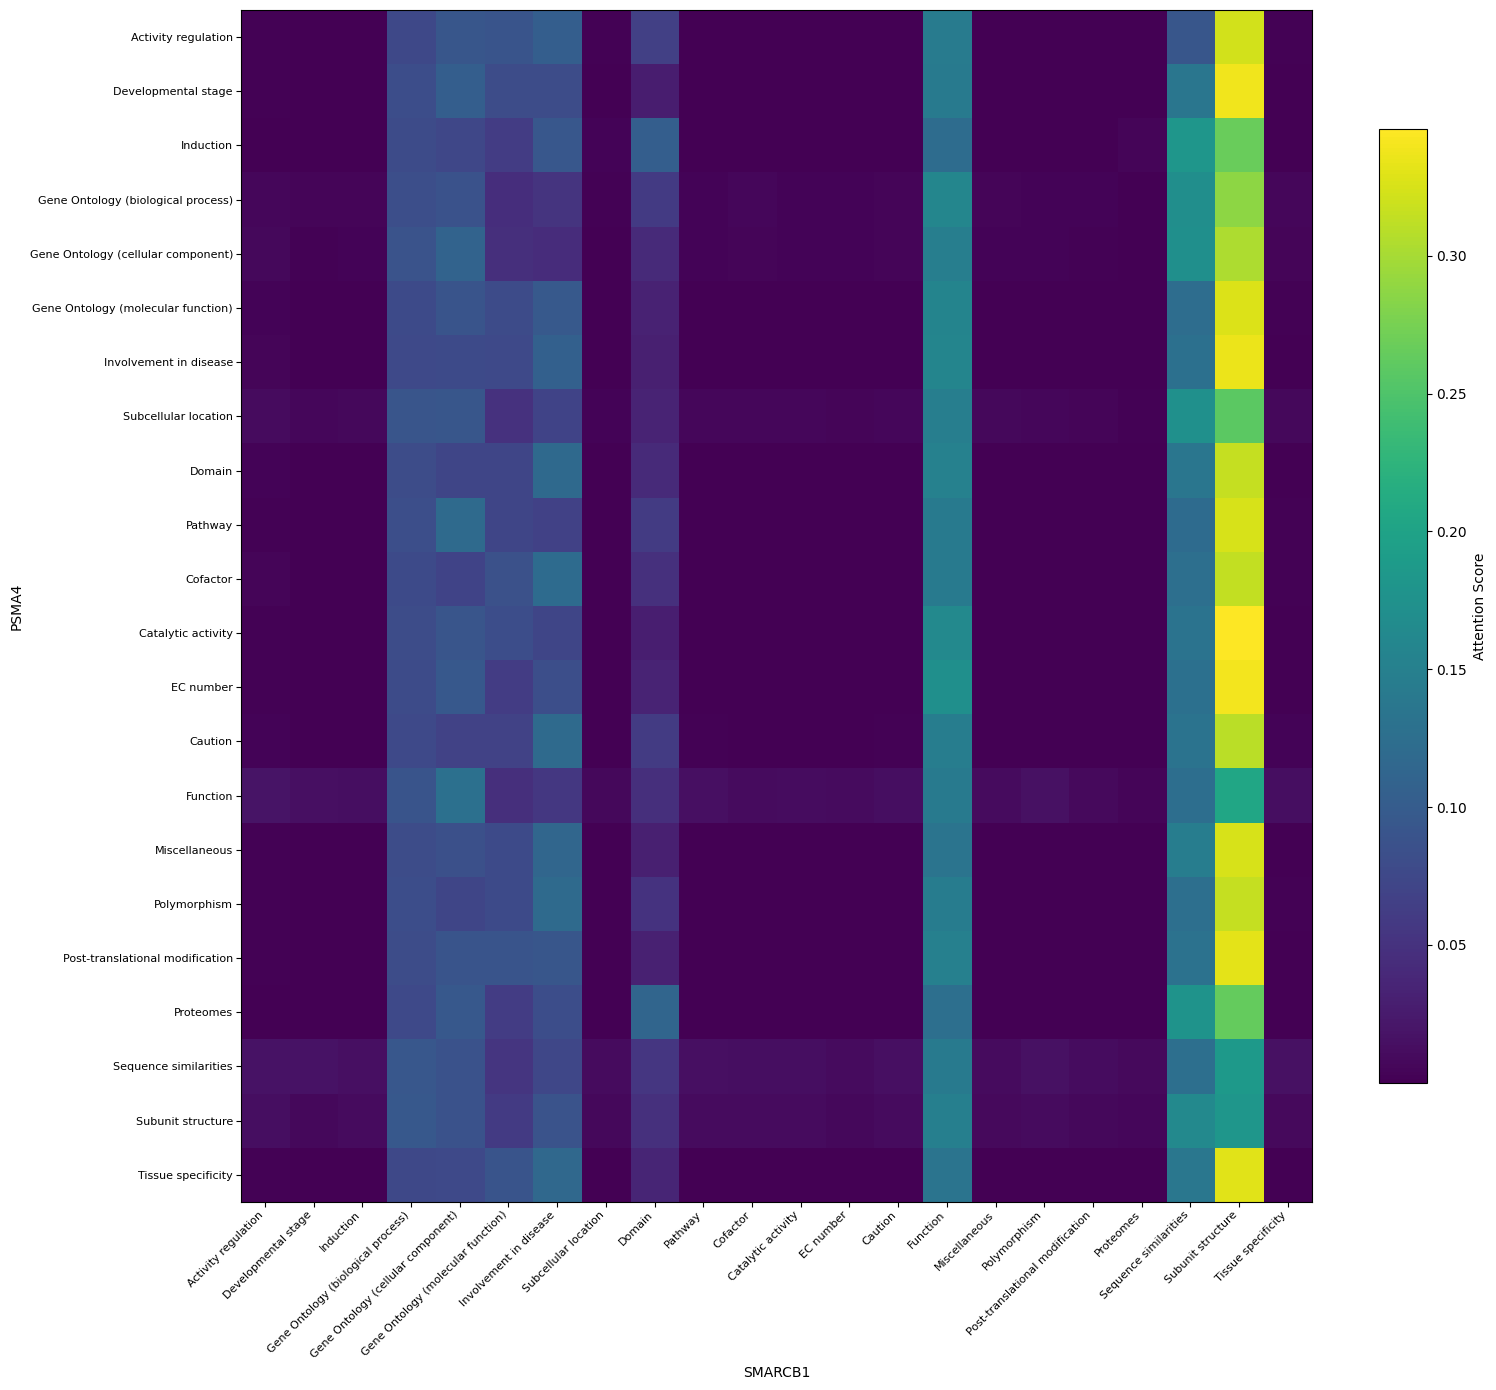

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# 1. 定义22个特征名称（按你给出的次序）
labels = [
    'Activity regulation',
    'Developmental stage',
    'Induction',
    'Gene Ontology (biological process)',
    'Gene Ontology (cellular component)',
    'Gene Ontology (molecular function)',
    'Involvement in disease',
    'Subcellular location',
    'Domain',
    'Pathway',
    'Cofactor',
    'Catalytic activity',
    'EC number',
    'Caution',
    'Function',
    'Miscellaneous',
    'Polymorphism',
    'Post-translational modification',
    'Proteomes',
    'Sequence similarities',
    'Subunit structure',
    'Tissue specificity'
]

# 2. 生成模拟的22×22注意力矩阵（替换为你的真实数据）
# 模拟数据：对角线注意力值高，其余随机，更贴近真实attention map特征
attention_map = torch.load(f'/data/qingyuyang/ESM4SL/output/pfnew/{experiment}/{scene}/fold_{fold}/att/{gene_a}_{gene_b}: {gene_a}.pt', map_location='cpu', weights_only=True)

# 3. 创建可视化画布（调整尺寸避免标签重叠）
fig, ax = plt.subplots(figsize=(16, 14))  # 画布尺寸，可根据需要调整

# 4. 绘制热力图（注意力图谱）
im = ax.imshow(attention_map, cmap='viridis', aspect='auto')

# 5. 设置坐标轴标签
ax.set_ylabel(gid2gn[gene_a])
ax.set_xlabel(gid2gn[gene_b])
# - 设置刻度位置（0-21对应22个特征）
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
# - 设置刻度标签（旋转x轴标签避免重叠）
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(labels, fontsize=8)

# 6. 优化刻度显示（隐藏刻度线，只保留标签）
ax.tick_params(top=False, bottom=True, left=True, right=False)
ax.tick_params(axis='x', pad=2)  # x轴标签与画布的间距
ax.tick_params(axis='y', pad=2)  # y轴标签与画布的间距

# 7. 添加颜色条（标注注意力值范围）
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('Attention Score', fontsize=10)

# 8. 添加标题和布局调整
# ax.set_title('Attention Map of Feature Correlation', fontsize=12, pad=20)
plt.tight_layout()  # 自动调整布局，避免元素重叠

# 9. 保存图片（可选，建议保存为高分辨率）
plt.savefig(f'{gid2gn[gene_a]}_{gid2gn[gene_b]}: {gid2gn[gene_a]}.jpg', dpi=300, bbox_inches='tight')

# 10. 显示图片
plt.show()

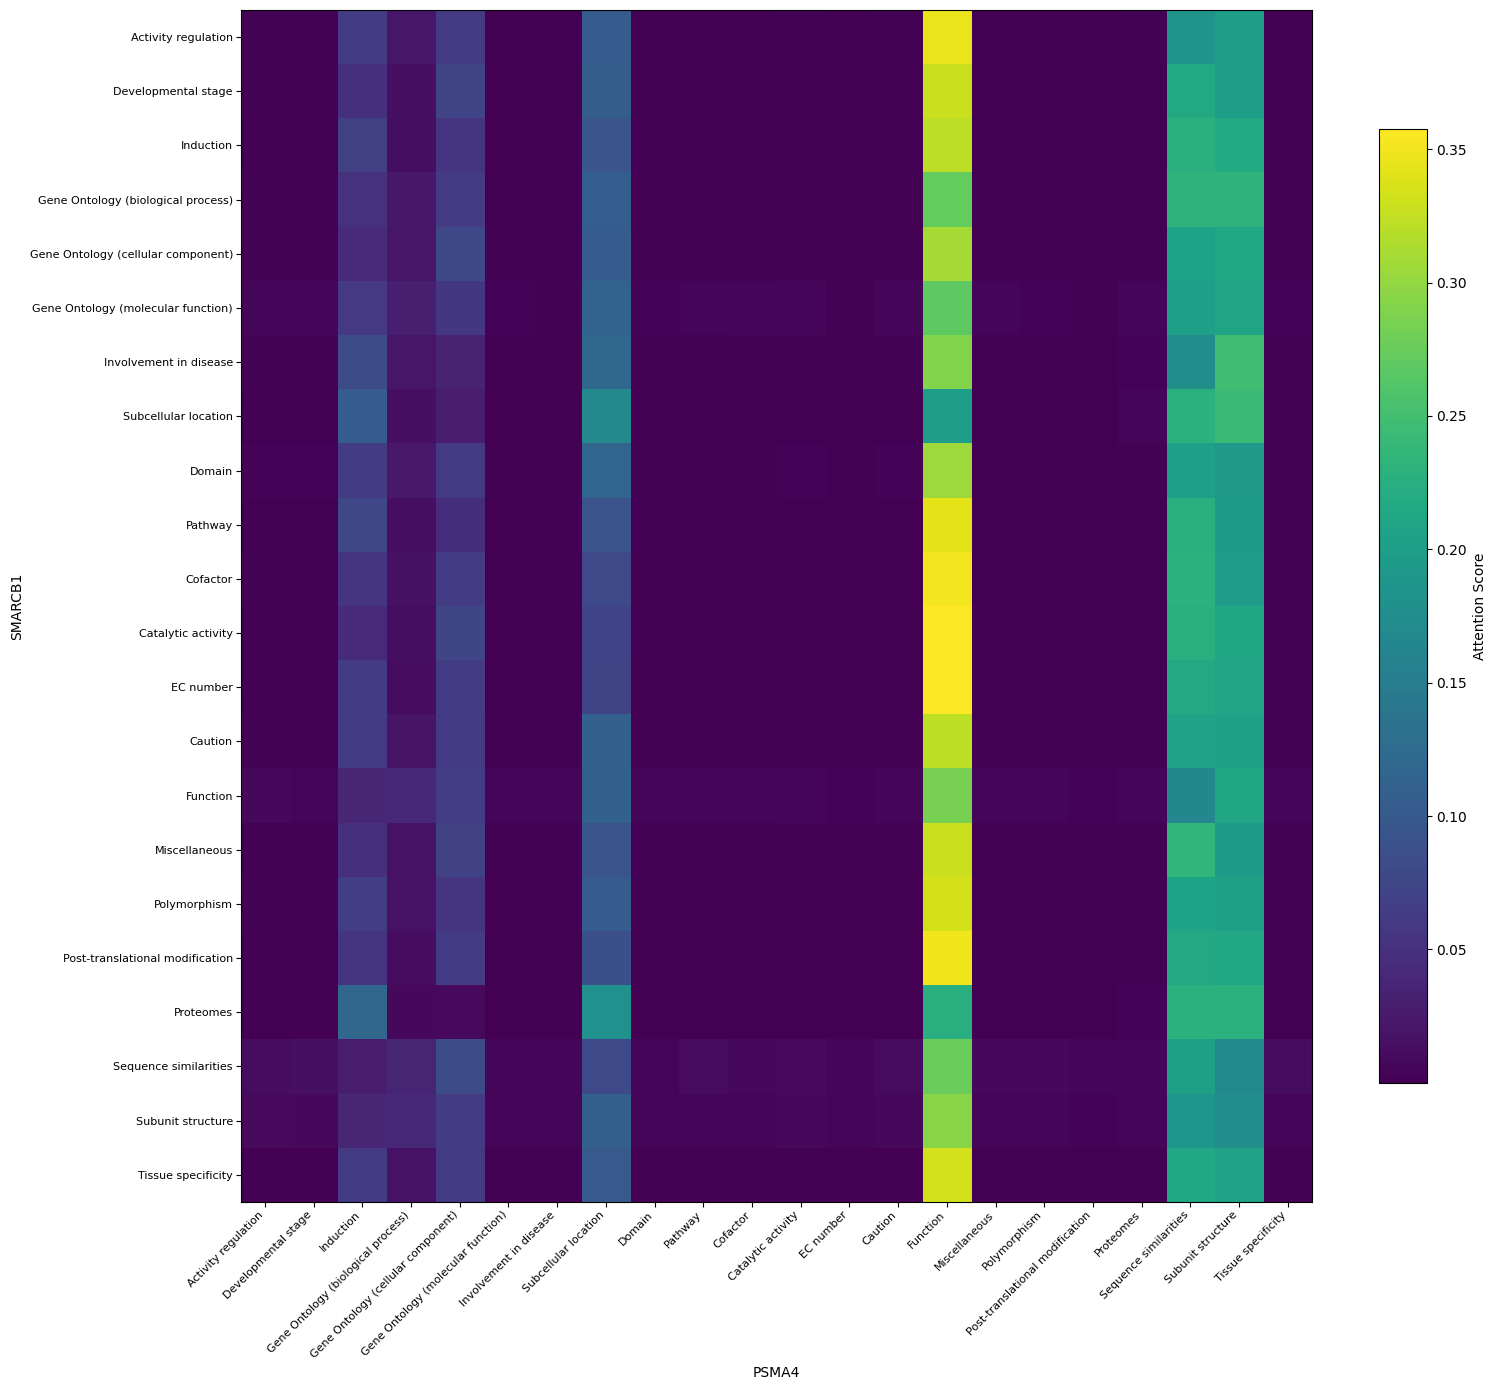

In [19]:
# 2. 生成模拟的22×22注意力矩阵（替换为你的真实数据）
# 模拟数据：对角线注意力值高，其余随机，更贴近真实attention map特征
attention_map = torch.load(f'/data/qingyuyang/ESM4SL/output/pfnew/{experiment}/{scene}/fold_{fold}/att/{gene_a}_{gene_b}: {gene_b}.pt', map_location='cpu', weights_only=True)

# 3. 创建可视化画布（调整尺寸避免标签重叠）
fig, ax = plt.subplots(figsize=(16, 14))  # 画布尺寸，可根据需要调整

# 4. 绘制热力图（注意力图谱）
im = ax.imshow(attention_map, cmap='viridis', aspect='auto')

# 5. 设置坐标轴标签
ax.set_ylabel(gid2gn[gene_b])
ax.set_xlabel(gid2gn[gene_a])
# - 设置刻度位置（0-21对应22个特征）
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
# - 设置刻度标签（旋转x轴标签避免重叠）
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(labels, fontsize=8)

# 6. 优化刻度显示（隐藏刻度线，只保留标签）
ax.tick_params(top=False, bottom=True, left=True, right=False)
ax.tick_params(axis='x', pad=2)  # x轴标签与画布的间距
ax.tick_params(axis='y', pad=2)  # y轴标签与画布的间距

# 7. 添加颜色条（标注注意力值范围）
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('Attention Score', fontsize=10)

# 8. 添加标题和布局调整
# ax.set_title('Attention Map of Feature Correlation', fontsize=12, pad=20)
plt.tight_layout()  # 自动调整布局，避免元素重叠

# 9. 保存图片（可选，建议保存为高分辨率）
plt.savefig(f'{gid2gn[gene_a]}_{gid2gn[gene_b]}: {gid2gn[gene_b]}.jpg', dpi=300, bbox_inches='tight')

# 10. 显示图片
plt.show()